[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhconning/hunter_eco701/blob/main/notebooks/topic01_definitions_key_tools_figures.ipynb)

# Topic 1: Definitions and Key Tools -- Figure Generator

This notebook generates, from a single underlying model, every static figure
used in [`slides/01_definitions-and-key-tools/deck.md`](../slides/01_definitions-and-key-tools/deck.md)
(the BFH-based "Mechanisms, Games, and Frontiers" lecture). Nothing in that
deck is a scanned or hand-drawn image: the payoff numbers in its tables and
every curve in its figures come from the model below, and this notebook
*asserts* the numbers before drawing, so the slides and the math can never
drift apart.

**The model** (from the 2018 course notes on the Bowles/Foley/Halliday draft;
the 2022 published edition, Bowles & Halliday *Microeconomics: Competition,
Conflict, and Coordination*, uses its discretized 2x2 form as Chapter 1's
Fishermen's Dilemma): two fishers choose hours $e_A, e_B$ with payoffs

$$u_A(e_A, e_B) = \left(15 - \tfrac{1}{4}e_B\right)e_A - \tfrac{1}{2}e_A^2$$

and symmetrically for $B$. Each extra hour Bob fishes lowers Alfredo's catch
per hour: a negative external effect, sitting inside a payoff function.

**Contents:**

1. Model + assertions that reproduce the deck's 2x2 payoff matrix (78/75/72/70)
2. Static figures, saved to `../slides/01_definitions-and-key-tools/figs/`:
   `foc_review.png`, `fd_reaction_curves.png`, `fd_payoff_space.png`,
   `fd_upf.png`, `ppf.png`
3. An interactive "externality knob" demo (`ipywidgets`): one parameter
   $\alpha$ morphs the game from commons over-use through invisible hand to
   public-goods under-provision

Run with the `ecopy` kernel (`mamba run -n ecopy jupyter lab`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY = "#24325c"
AMBER = "#b8842a"
BRICK = "#a04434"

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
})

FIGDIR = Path("../slides/01_definitions-and-key-tools/figs")
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")

## 1. The model behind the deck's numbers

Best response: $\partial u_A/\partial e_A = 15 - \tfrac14 e_B - e_A = 0$, so
$e_A^{BR}(e_B) = 15 - \tfrac14 e_B$ (concave: SOC $= -1 < 0$).

With a general interference coefficient $\alpha$ (the deck uses $\alpha = \tfrac14$):

- symmetric **Nash** effort $e^* = \dfrac{15}{1+\alpha}$ ($= 12$ at $\alpha = \tfrac14$)
- symmetric **joint-surplus (planner)** effort $e^P = \dfrac{15}{1+2\alpha}$ ($= 10$),
  from the planner's FOC, which adds the external-cost term
  $\partial u_B/\partial e_A = -\alpha e_B$ to the private one.

Restricting strategies to $\{10, 12\}$ gives the deck's payoff matrix, a strict
Prisoners' Dilemma: $78 > 75 > 72 > 70$ (and $2\cdot 75 > 78 + 70$). Maximum
joint surplus is $2 \times 75 = 150$ at $(10, 10)$, so with transferable
payoffs the utility possibility frontier is the line $u_A + u_B = 150$.

In [2]:
def u(eA, eB, alpha=0.25):
    "Payoff to a fisher choosing hours eA when the other fishes eB."
    return (15 - alpha * eB) * eA - 0.5 * eA**2

def br(eB, alpha=0.25):
    "Best-response hours to the other's eB."
    return 15 - alpha * eB

def e_nash(alpha=0.25):
    return 15 / (1 + alpha)

def e_planner(alpha=0.25):
    return 15 / (1 + 2 * alpha)

# The deck's 2x2: strategies restricted to 10 or 12 hours
matrix = {(a, b): (u(a, b), u(b, a)) for a in (10, 12) for b in (10, 12)}
for profile, payoffs in sorted(matrix.items()):
    print(f"(A: {profile[0]}h, B: {profile[1]}h) -> {payoffs}")

# Assert exactly the numbers printed on the slides
assert matrix[(10, 10)] == (75.0, 75.0)
assert matrix[(10, 12)] == (70.0, 78.0)
assert matrix[(12, 10)] == (78.0, 70.0)
assert matrix[(12, 12)] == (72.0, 72.0)

# Nash and planner efforts quoted on the slides
assert abs(e_nash() - 12) < 1e-12
assert abs(e_planner() - 10) < 1e-12

# Prisoners' Dilemma conditions: y > w > z > x and 2w > x + y
y_, w_, z_, x_ = 78, 75, 72, 70
assert y_ > w_ > z_ > x_ and 2 * w_ > x_ + y_

# Liability rule: defector compensates the harmed party's loss (w - x = 5)
assert (y_ - (w_ - x_), x_ + (w_ - x_)) == (73, 75)  # defect-vs-cooperate cell
print("all payoff assertions pass")

(A: 10h, B: 10h) -> (75.0, 75.0)
(A: 10h, B: 12h) -> (70.0, 78.0)
(A: 12h, B: 10h) -> (78.0, 70.0)
(A: 12h, B: 12h) -> (72.0, 72.0)
all payoff assertions pass


## 2. Static figures for the deck

saved ..\slides\01_definitions-and-key-tools\figs\foc_review.png


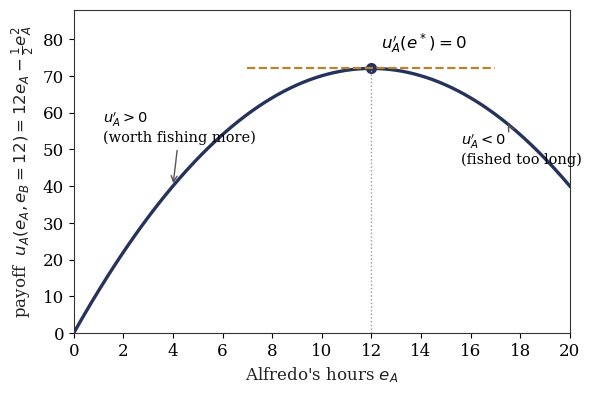

In [3]:
# foc_review.png -- calculus review on the model's own objective:
# Alfredo's payoff u_A(e, 12) given Bob fishes 12 hours; peak at e* = BR(12) = 12.
fig, ax = plt.subplots(figsize=(6.4, 4.2))
e = np.linspace(0, 20, 400)
uA = u(e, 12)
ax.plot(e, uA, color=NAVY, lw=2.4)
ax.plot([12], [72], "o", ms=7, color=NAVY)
ax.plot([7, 17], [72, 72], ls="--", color=AMBER, lw=1.6)
ax.plot([12, 12], [0, 72], ls=":", color="#999999", lw=1.0)
ax.annotate(r"$u_A'(e^*) = 0$", xy=(12, 72), xytext=(12.4, 77.5), fontsize=12)
ax.annotate(r"$u_A' > 0$" + "\n(worth fishing more)", xy=(4, u(4, 12)),
            xytext=(1.2, 52), fontsize=10.5,
            arrowprops=dict(arrowstyle="->", color="#555555", lw=1.0))
ax.annotate(r"$u_A' < 0$" + "\n(fished too long)", xy=(17.5, u(17.5, 12)),
            xytext=(15.6, 46), fontsize=10.5,
            arrowprops=dict(arrowstyle="->", color="#555555", lw=1.0))
ax.set_xlim(0, 20)
ax.set_ylim(0, 88)
ax.set_xticks(range(0, 21, 2))
ax.set_xlabel(r"Alfredo's hours $e_A$")
ax.set_ylabel(r"payoff  $u_A(e_A, e_B{=}12) = 12e_A - \frac{1}{2}e_A^2$")
savefig(fig, "foc_review.png")

saved ..\slides\01_definitions-and-key-tools\figs\fd_reaction_curves.png


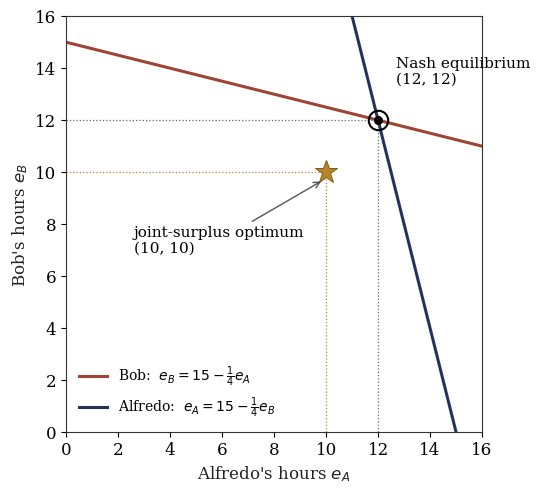

In [4]:
# fd_reaction_curves.png -- best-response functions, Nash (12,12), planner (10,10)
fig, ax = plt.subplots(figsize=(5.8, 5.4))
e = np.linspace(0, 16, 200)
ax.plot(e, br(e), color=BRICK, lw=2.2,
        label=r"Bob:  $e_B = 15 - \frac{1}{4}e_A$")
ax.plot(br(e), e, color=NAVY, lw=2.2,
        label=r"Alfredo:  $e_A = 15 - \frac{1}{4}e_B$")
for v, c in (((12, 12), "#666666"), ((10, 10), "#b8842a")):
    ax.plot([v[0], v[0]], [0, v[1]], ls=":", color=c, lw=0.9)
    ax.plot([0, v[0]], [v[1], v[1]], ls=":", color=c, lw=0.9)
ax.plot([12], [12], marker="o", ms=14, mfc="none", mec="black", mew=1.5)
ax.plot([12], [12], marker="o", ms=5.5, color="black")
ax.annotate("Nash equilibrium\n(12, 12)", xy=(12, 12), xytext=(12.7, 13.4),
            fontsize=11)
ax.plot([10], [10], marker="*", ms=17, color=AMBER, mec="#7a5a10", mew=0.7)
ax.annotate("joint-surplus optimum\n(10, 10)", xy=(9.9, 9.7), xytext=(2.6, 6.9),
            fontsize=11, arrowprops=dict(arrowstyle="->", color="#555555", lw=1.0))
ax.set_xlim(0, 16)
ax.set_ylim(0, 16)
ax.set_xticks(range(0, 17, 2))
ax.set_yticks(range(0, 17, 2))
ax.set_xlabel(r"Alfredo's hours $e_A$")
ax.set_ylabel(r"Bob's hours $e_B$")
ax.set_aspect("equal")
ax.legend(loc="lower left", fontsize=10, frameon=False)
savefig(fig, "fd_reaction_curves.png")

saved ..\slides\01_definitions-and-key-tools\figs\fd_payoff_space.png


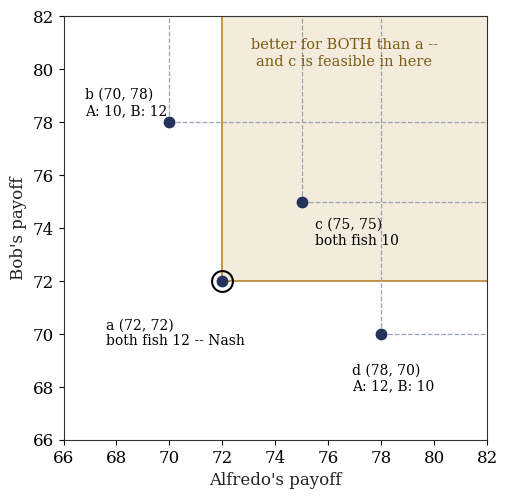

In [5]:
# fd_payoff_space.png -- the four outcomes in payoff space, BFH Fig 1.13 style:
# the Nash outcome a is the one point with a feasible point (c) in its
# better-for-both region; b, c, d have empty "northeast shadows".
pts = {
    "a": (72, 72, "both fish 12\n(Nash equilibrium)"),
    "b": (70, 78, "A: 10, B: 12"),
    "c": (75, 75, "both fish 10"),
    "d": (78, 70, "A: 12, B: 10"),
}
lo, hi = 66, 82
fig, ax = plt.subplots(figsize=(5.9, 5.5))
ax.fill_between([72, hi], 72, hi, color=AMBER, alpha=0.16, lw=0)
ax.plot([72, hi], [72, 72], color=AMBER, lw=1.2)
ax.plot([72, 72], [72, hi], color=AMBER, lw=1.2)
for k in ("b", "c", "d"):
    x0, y0, _ = pts[k]
    ax.plot([x0, hi], [y0, y0], ls="--", color="#9aa3b2", lw=0.9)
    ax.plot([x0, x0], [y0, hi], ls="--", color="#9aa3b2", lw=0.9)
for k, (x0, y0, lab) in pts.items():
    ax.plot([x0], [y0], "o", ms=7.5, color=NAVY, zorder=5)
ax.plot([72], [72], marker="o", ms=15, mfc="none", mec="black", mew=1.5, zorder=6)
ax.annotate("a (72, 72)\nboth fish 12 -- Nash", xy=(72, 72), xytext=(67.6, 70.6),
            fontsize=10, ha="left", va="top")
ax.annotate("b (70, 78)\nA: 10, B: 12", xy=(70, 78), xytext=(66.8, 79.3),
            fontsize=10, ha="left", va="top")
ax.annotate("c (75, 75)\nboth fish 10", xy=(75, 75), xytext=(75.5, 74.4),
            fontsize=10, ha="left", va="top")
ax.annotate("d (78, 70)\nA: 12, B: 10", xy=(78, 70), xytext=(76.9, 68.9),
            fontsize=10, ha="left", va="top")
ax.annotate("better for BOTH than a --\nand c is feasible in here", xy=(75, 75),
            xytext=(76.6, 80.6), fontsize=10.5, color="#7a5a10", ha="center",
            va="center")
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_xlabel("Alfredo's payoff")
ax.set_ylabel("Bob's payoff")
ax.set_aspect("equal")
savefig(fig, "fd_payoff_space.png")

saved ..\slides\01_definitions-and-key-tools\figs\fd_upf.png


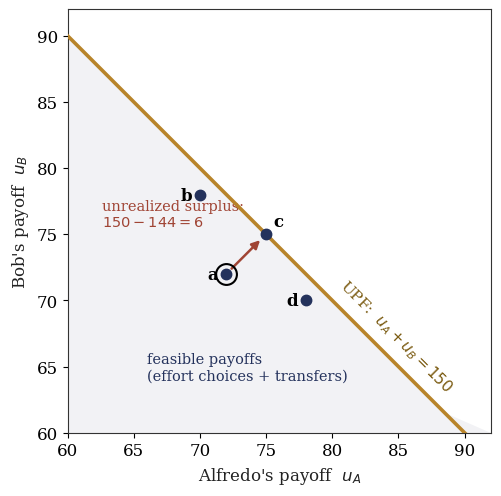

In [6]:
# fd_upf.png -- transferable-utility UPF u_A + u_B = 150 through (75, 75);
# all four game outcomes lie on or inside it; the Nash outcome wastes 6.
lo, hi = 60, 92
fig, ax = plt.subplots(figsize=(5.9, 5.5))
xs = np.linspace(lo, hi, 10)
ax.fill_between(xs, lo, np.clip(150 - xs, lo, hi), color=NAVY, alpha=0.06, lw=0)
ax.plot(xs, 150 - xs, color=AMBER, lw=2.6, zorder=4)
ax.text(84.3, 150 - 84.3 + 1.1, "UPF:  $u_A + u_B = 150$", rotation=-45,
        fontsize=11, color="#7a5a10", ha="center", va="bottom",
        rotation_mode="anchor")
pts = {"a": (72, 72), "b": (70, 78), "c": (75, 75), "d": (78, 70)}
for k, (x0, y0) in pts.items():
    ax.plot([x0], [y0], "o", ms=7.5, color=NAVY, zorder=5)
    dx, dy = (-2.6, -0.4) if k != "c" else (1.0, 0.6)
    ax.annotate(k, xy=(x0, y0), xytext=(x0 + dx * 0.55, y0 + dy), fontsize=12,
                fontweight="bold")
ax.plot([72], [72], marker="o", ms=15, mfc="none", mec="black", mew=1.5, zorder=6)
ax.annotate("", xy=(74.7, 74.7), xytext=(72.25, 72.25),
            arrowprops=dict(arrowstyle="-|>", color=BRICK, lw=1.8))
ax.annotate("unrealized surplus:\n$150 - 144 = 6$", xy=(73.5, 73.5),
            xytext=(62.6, 75.6), fontsize=10.5, color=BRICK)
ax.annotate("feasible payoffs\n(effort choices + transfers)", xy=(66, 64),
            fontsize=10.5, color=NAVY, ha="left")
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_xlabel("Alfredo's payoff  $u_A$")
ax.set_ylabel("Bob's payoff  $u_B$")
ax.set_aspect("equal")
savefig(fig, "fd_upf.png")

saved ..\slides\01_definitions-and-key-tools\figs\ppf.png


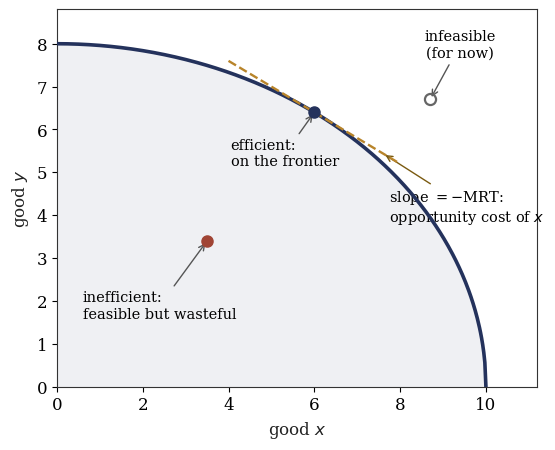

In [7]:
# ppf.png -- production possibility frontier with efficient / inefficient /
# infeasible points and the MRT as the frontier's slope. Replaces the old
# textbook-scan sample_fig.png.
a_, b_ = 10, 8
fig, ax = plt.subplots(figsize=(6.2, 4.9))
x = np.linspace(0, a_, 400)
y = b_ * np.sqrt(1 - (x / a_) ** 2)
ax.plot(x, y, color=NAVY, lw=2.6, zorder=4)
ax.fill_between(x, 0, y, color=NAVY, alpha=0.07, lw=0)
xF, yF = 6.0, b_ * np.sqrt(1 - 0.36)          # on the frontier
slope = -(b_**2 * xF) / (a_**2 * yF)           # dy/dx = -MRT
xt = np.linspace(xF - 2.0, xF + 2.0, 10)
ax.plot(xt, yF + slope * (xt - xF), ls="--", color=AMBER, lw=1.7, zorder=5)
ax.plot([xF], [yF], "o", ms=8, color=NAVY, zorder=6)
ax.plot([3.5], [3.4], "o", ms=8, color=BRICK, zorder=6)
ax.plot([8.7], [6.7], "o", ms=8, mfc="none", mec="#666666", mew=1.6, zorder=6)
ax.annotate("efficient:\non the frontier", xy=(xF, yF), xytext=(4.05, 5.15),
            fontsize=10.5, ha="left",
            arrowprops=dict(arrowstyle="->", color="#555555", lw=1.0))
ax.annotate("inefficient:\nfeasible but wasteful", xy=(3.5, 3.4),
            xytext=(0.6, 1.6), fontsize=10.5,
            arrowprops=dict(arrowstyle="->", color="#555555", lw=1.0))
ax.annotate("infeasible\n(for now)", xy=(8.7, 6.7), xytext=(9.4, 7.7),
            fontsize=10.5, ha="center",
            arrowprops=dict(arrowstyle="->", color="#555555", lw=1.0))
ax.annotate("slope $= -$MRT:\nopportunity cost of $x$",
            xy=(7.6, yF + slope * 1.6), xytext=(7.75, 3.85), fontsize=10.5,
            arrowprops=dict(arrowstyle="->", color="#7a5a10", lw=1.0))
ax.set_xlim(0, 11.2)
ax.set_ylim(0, 8.8)
ax.set_xlabel("good $x$")
ax.set_ylabel("good $y$")
savefig(fig, "ppf.png")

## 3. Interactive demo: one externality knob, three kinds of economy

Generalize to $u_A = (15 - \alpha e_B)e_A - \tfrac12 e_A^2$. Then
$e^{Nash} = \frac{15}{1+\alpha}$ and $e^{planner} = \frac{15}{1+2\alpha}$:

- $\alpha > 0$ (my fishing hurts you): **commons** -- Nash effort exceeds the
  efficient level (over-use);
- $\alpha = 0$: no external effect -- private and social optima coincide
  (**invisible hand**, trivially);
- $\alpha < 0$ (my effort helps you -- knowledge, planting early): Nash effort
  falls short (**under-provision**, the public-goods problem of Topic 9).

Drag the slider in a live session; the static export below shows $\alpha = 1/4$.

In [8]:
def alpha_demo(alpha=0.25):
    es, ep = e_nash(alpha), e_planner(alpha)
    top = max(18.0, 1.2 * max(es, ep))
    e = np.linspace(0, top, 300)
    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    ax.plot(e, br(e, alpha), color=BRICK, lw=2, label="Bob's best response")
    ax.plot(br(e, alpha), e, color=NAVY, lw=2, label="Alfredo's best response")
    ax.plot([es], [es], marker="o", ms=13, mfc="none", mec="black", mew=1.4)
    ax.plot([es], [es], marker="o", ms=5, color="black")
    ax.plot([ep], [ep], marker="*", ms=16, color=AMBER, mec="#7a5a10", mew=0.7)
    if alpha > 0:
        regime = "alpha > 0: commons -- Nash over-uses"
    elif alpha == 0:
        regime = "alpha = 0: no externality -- Nash = efficient"
    else:
        regime = "alpha < 0: spillovers -- Nash under-provides"
    ax.set_title(f"{regime}\nNash e* = {es:.2f},  efficient e = {ep:.2f}",
                 fontsize=11)
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_xlabel(r"$e_A$")
    ax.set_ylabel(r"$e_B$")
    ax.set_aspect("equal")
    ax.legend(loc="lower left", fontsize=9, frameon=False)
    plt.show()

try:
    from ipywidgets import interact, FloatSlider
    interact(alpha_demo,
             alpha=FloatSlider(value=0.25, min=-0.2, max=0.6, step=0.05,
                               description=r"alpha"))
except ImportError:
    alpha_demo(0.25)

interactive(children=(FloatSlider(value=0.25, description='alpha', max=0.6, min=-0.2, step=0.05), Output()), _…

## Promotion note

Figures land in `slides/01_definitions-and-key-tools/figs/` (git-tracked,
regeneratable, never hand-edited). The copies the deck actually references
live in `media/` under the same filenames; promoting a regenerated figure is
a deliberate `cp figs/<name>.png media/<name>.png` -- see HANDOFF.md's
"Code-generated figures" section. Deck usage: `foc_review.png` (calculus
review), `fd_reaction_curves.png` (best-response functions),
`fd_payoff_space.png` (Pareto comparisons), `fd_upf.png` (UPF),
`ppf.png` (PPF).